# CS781 Phase 1 — Arch 1: Decoder-only Transformer (`ARCH = "llama"`)
One self-contained notebook per architecture, so the 4 notebooks can run **at the same time** on 4 Colab accounts.

| | |
|---|---|
| Model | `LlamaForCausalLM` (RoPE, RMSNorm, SwiGLU), random init |
| Objective | next-token prediction on every token |
| Checkpoints | private repo `<hf-user>/cs781-p1-llama`: `latest/` = resumable training state, `best/` = best validation loss |

**Before you start**
1. `00_data_prep.ipynb` has finished once (it creates the private dataset repo `<hf-user>/cs781-p1-data`).
2. Runtime -> Change runtime type -> **T4 GPU**.
3. Secrets (key icon) -> `HF` = the **same** HF write token used in `00_data_prep`, notebook access ON.

**Run all.** Part A trains for `TRAIN_HOURS`; Part B generates on the local held-out set and the official test
prompts and writes `submission.zip`.
- Colab disconnected? Reconnect and **Run all** again: training resumes from `latest/`; if training had already
  finished it goes straight to Part B.
- Another submission later (e.g. different decoding)? Run the cells up to and including *Configuration*, then run
  Part B with a new `RUN_TAG`.

In [1]:
!pip -q install bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.1 MB/s eta 0:00:00


In [2]:
ARCH = "llama"   # fixed for this notebook; each architecture has its own notebook

In [3]:
import os, json, math, time, shutil, random, gc
import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

# A failed upload (network blip, Hub hiccup) must not kill a multi-hour run: retry, then log and keep going.
def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

assert torch.cuda.is_available(), "Switch the runtime to a GPU"
print(torch.__version__, torch.cuda.get_device_name(0))
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.18.0


## Configuration — **all values below are YOUR CHOICE** (document them in the report)

In [4]:
DATA_REPO = f"{HF_USER}/cs781-p1-data"
MODEL_REPO = f"{HF_USER}/cs781-p1-{ARCH}"
WORK = "/content/p1_train" if os.path.isdir("/content") else "/tmp/p1_train"
os.makedirs(WORK, exist_ok=True)

# Data mixing weights per source (sampling probability of each training window)
MIX = {"sc": 0.35, "hc": 0.35, "trib": 0.15, "acts": 0.15}

# Training budget: wall-clock hours of pure training (the LR schedule is fitted to this)
TRAIN_HOURS = 3
CKPT_MINUTES = 30
EVAL_EVERY = 250          # optimizer steps
EVAL_BATCHES_PER_SOURCE = 10

# Optimisation
LR = 6e-4
MIN_LR_FRAC = 0.1
WARMUP_STEPS = 300
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
GRAD_CLIP = 1.0
MICRO_BS = 8
GRAD_ACCUM = 8
DROPOUT = 0.0
SEED = 42

# Sequence lengths
CTX = 1024                 # decoder-only / prefix-LM window
PREFIX_MIN = 64            # prefix-LM: prefix length sampled in [PREFIX_MIN, CTX - 128]
SRC_MIN, SRC_MAX = 128, 768   # bart: encoder length sampled in this range
TGT_LEN = 256              # bart: decoder (continuation) length

# Model sizes
D_MODEL, N_LAYER, N_HEAD, D_FF = 768, 12, 12, 2048
N_KV_HEAD_SWA, SWA_WINDOW = 4, 256                   # mistral_swa only
BART_ENC_LAYERS, BART_DEC_LAYERS, BART_FF = 6, 6, 3072  # bart only

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Part A — Training
## Data: per-source token memmaps

In [5]:
if not api.file_exists(DATA_REPO, "meta.json", repo_type="dataset"):
    raise RuntimeError(f"{DATA_REPO} has no meta.json yet -- run 00_data_prep.ipynb to completion first "
                       "(with the same HF token as this notebook's `HF` secret).")
data_dir = snapshot_download(DATA_REPO, repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["*.bin", "meta.json", "tokenizer/*"])
meta = json.load(open(f"{data_dir}/meta.json"))
SOURCES = [s for s in meta["sources"] if MIX.get(s, 0) > 0]
weights = np.array([MIX[s] for s in SOURCES], dtype=np.float64); weights /= weights.sum()
bins = {split: {s: np.memmap(f"{data_dir}/{s}_{split}.bin", dtype=np.uint16, mode="r") for s in SOURCES}
        for split in ("train", "val")}
for s in SOURCES:
    print(f"{s:5s} train {len(bins['train'][s])/1e6:8.1f}M  val {len(bins['val'][s])/1e6:6.2f}M  weight {MIX[s]:.2f}")

from transformers import PreTrainedTokenizerFast
tokenizer = PreTrainedTokenizerFast.from_pretrained(f"{data_dir}/tokenizer")
VOCAB, EOS_ID, PAD_ID = len(tokenizer), tokenizer.eos_token_id, tokenizer.pad_token_id
print("vocab", VOCAB, "eos", EOS_ID, "pad", PAD_ID)

WINDOW = SRC_MAX + TGT_LEN if ARCH == "bart" else CTX

def sample_windows(split, n, length, rng, source=None):
    out = np.empty((n, length), dtype=np.int64)
    srcs = [source] * n if source else rng.choice(SOURCES, size=n, p=weights)
    for i, s in enumerate(srcs):
        arr = bins[split][s]
        j = int(rng.integers(0, len(arr) - length - 1))
        out[i] = arr[j:j + length]
    return torch.from_numpy(out)

# fixed validation windows per source (identical for every run of the same ARCH family)
val_rng = np.random.default_rng(0)
VAL_SET = {s: [sample_windows("val", MICRO_BS, WINDOW, val_rng, source=s) for _ in range(EVAL_BATCHES_PER_SOURCE)]
           for s in SOURCES}

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

sc    train    252.5M  val   2.70M  weight 0.35
hc    train    396.6M  val   3.67M  weight 0.35
trib  train    250.3M  val   2.78M  weight 0.15
acts  train     75.0M  val   1.14M  weight 0.15
vocab 32000 eos 0 pad 1


## Model (Hugging Face classes, randomly initialised — no pretrained weights)

In [6]:
from transformers import (LlamaConfig, LlamaForCausalLM, MistralConfig, MistralForCausalLM,
                          BartConfig, BartForConditionalGeneration)

def build_model():
    common = dict(vocab_size=VOCAB, bos_token_id=EOS_ID, eos_token_id=EOS_ID, pad_token_id=PAD_ID)
    if ARCH in ("llama", "prefixlm"):
        cfg = LlamaConfig(hidden_size=D_MODEL, intermediate_size=D_FF, num_hidden_layers=N_LAYER,
                          num_attention_heads=N_HEAD, num_key_value_heads=N_HEAD, max_position_embeddings=CTX,
                          attention_dropout=DROPOUT, tie_word_embeddings=True, **common)
        m = LlamaForCausalLM(cfg)
    elif ARCH == "mistral_swa":
        cfg = MistralConfig(hidden_size=D_MODEL, intermediate_size=D_FF, num_hidden_layers=N_LAYER,
                            num_attention_heads=N_HEAD, num_key_value_heads=N_KV_HEAD_SWA,
                            sliding_window=SWA_WINDOW, max_position_embeddings=CTX,
                            attention_dropout=DROPOUT, tie_word_embeddings=True, **common)
        m = MistralForCausalLM(cfg)
    elif ARCH == "bart":
        cfg = BartConfig(d_model=D_MODEL, encoder_layers=BART_ENC_LAYERS, decoder_layers=BART_DEC_LAYERS,
                         encoder_attention_heads=N_HEAD, decoder_attention_heads=N_HEAD,
                         encoder_ffn_dim=BART_FF, decoder_ffn_dim=BART_FF, max_position_embeddings=1024,
                         dropout=DROPOUT, attention_dropout=DROPOUT, activation_dropout=0.0,
                         decoder_start_token_id=EOS_ID, forced_bos_token_id=None, forced_eos_token_id=None,
                         scale_embedding=True, tie_word_embeddings=True, **common)
        m = BartForConditionalGeneration(cfg)
    else:
        raise ValueError(ARCH)
    m.config.cs781_arch = ARCH          # read by the generation notebook
    return m

model = build_model()
n_params = sum(p.numel() for p in model.parameters())
print(f"{ARCH}: {n_params/1e6:.1f}M parameters")
assert 50e6 <= n_params <= 300e6, "Phase-1 rule: 50M-300M parameters"
model = model.cuda()

llama: 109.5M parameters


## Objectives
Prefix-LM: tokens `< P` attend bidirectionally among themselves; tokens `>= P` are causal. Loss only on positions `>= P`
(predicting prefix tokens would leak, since the prefix sees itself bidirectionally).

In [7]:
def prefix_mask(B, L, P, device):
    i = torch.arange(L, device=device)
    allowed = (i[None, :] <= i[:, None]) | (i[None, :] < P)      # [query, key]
    return allowed[None, None].expand(B, 1, L, L)                  # bool, True = attend

def compute_loss(batch, rng, fixed=False):
    batch = batch.cuda(non_blocking=True)
    B, L = batch.shape
    if ARCH in ("llama", "mistral_swa"):
        return model(input_ids=batch, labels=batch).loss
    if ARCH == "prefixlm":
        P = L // 2 if fixed else int(rng.integers(PREFIX_MIN, L - 128))
        labels = batch.clone(); labels[:, :P] = -100
        return model(input_ids=batch, attention_mask=prefix_mask(B, L, P, batch.device), labels=labels).loss
    if ARCH == "bart":
        S = SRC_MAX if fixed else int(rng.integers(SRC_MIN, SRC_MAX + 1))
        src = batch[:, SRC_MAX - S:SRC_MAX].contiguous()
        tgt = batch[:, SRC_MAX:SRC_MAX + TGT_LEN].contiguous()
        return model(input_ids=src, labels=tgt).loss

## Sanity checks (prefix mask really is bidirectional on the prefix and causal after it)

In [8]:
if ARCH == "prefixlm":
    model.eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        x = sample_windows("val", 2, 64, np.random.default_rng(1)).cuda()
        ref = model(input_ids=x).logits.float()
        a = model(input_ids=x, attention_mask=prefix_mask(2, 64, 0, x.device)).logits.float()
        assert torch.allclose(ref, a, atol=2e-2), "4D mask ignored / misread by this transformers version"
        P = 32; x2 = x.clone(); x2[:, P - 1] = (x2[:, P - 1] + 1) % VOCAB
        b1 = model(input_ids=x, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        b2 = model(input_ids=x2, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        assert (b1[:, 0] - b2[:, 0]).abs().max() > 1e-5, "prefix is not bidirectional"
        x3 = x.clone(); x3[:, 50] = (x3[:, 50] + 1) % VOCAB
        b3 = model(input_ids=x3, attention_mask=prefix_mask(2, 64, P, x.device)).logits.float()
        assert torch.allclose(b1[:, :50], b3[:, :50], atol=2e-2), "suffix is not causal"
    print("prefix-LM mask checks passed")
model.train()

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 768, padding_idx=1)
    (layers): ModuleList(
      (0-11): 12 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=False)
          (k_proj): Linear(in_features=768, out_features=768, bias=False)
          (v_proj): Linear(in_features=768, out_features=768, bias=False)
          (o_proj): Linear(in_features=768, out_features=768, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=768, out_features=2048, bias=False)
          (up_proj): Linear(in_features=768, out_features=2048, bias=False)
          (down_proj): Linear(in_features=2048, out_features=768, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((768,), eps=1e-06)
        (post_attention_layernorm): LlamaRMSNorm((768,), eps=1e-06)
      )
    )
    (norm): LlamaRMSNorm((768,), eps=1e-06)
    (r

## Optimiser, schedule, checkpoint / resume

In [9]:
decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
opt = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                         {"params": no_decay, "weight_decay": 0.0}], lr=LR, betas=BETAS, fused=True)
scaler = torch.amp.GradScaler("cuda")

def lr_at(step, max_steps):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = min(1.0, (step - WARMUP_STEPS) / max(1, max_steps - WARMUP_STEPS))
    return LR * (MIN_LR_FRAC + (1 - MIN_LR_FRAC) * 0.5 * (1 + math.cos(math.pi * prog)))

state = {"step": 0, "max_steps": None, "best_val": float("inf"), "history": [], "train_seconds": 0.0, "tokens": 0}
api.create_repo(MODEL_REPO, private=True, exist_ok=True)
if api.file_exists(MODEL_REPO, "latest/state.pt"):
    ck = torch.load(hf_hub_download(MODEL_REPO, "latest/state.pt", token=HF_TOKEN, force_download=True),
                    map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    state = ck["state"]
    print(f"RESUMED from step {state['step']} / {state['max_steps']}")
    del ck
else:
    print("No checkpoint found, starting fresh")

# Every push of latest/ (~1.3 GB with optimizer state) adds a new LFS version to the repo history. Squashing the
# history after each push keeps only the newest latest/ and best/, so 4 repos stay well inside the HF storage quota.
SQUASH_HISTORY = True

def push_latest():
    d = f"{WORK}/latest"; shutil.rmtree(d, ignore_errors=True); os.makedirs(d)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "state": state},
               f"{d}/state.pt")
    json.dump(state["history"], open(f"{d}/history.json", "w"))
    hub_push(lambda: api.upload_folder(folder_path=d, path_in_repo="latest", repo_id=MODEL_REPO,
                                       commit_message=f"latest step {state['step']}"), "latest/")
    if SQUASH_HISTORY:
        hub_push(lambda: api.super_squash_history(repo_id=MODEL_REPO), "history squash", tries=1)

def push_best(val):
    d = f"{WORK}/best"; shutil.rmtree(d, ignore_errors=True)
    model.save_pretrained(d); tokenizer.save_pretrained(d)
    json.dump({"step": state["step"], "val_loss": val, "arch": ARCH, "params": n_params,
               "tokens_seen": state["tokens"]}, open(f"{d}/cs781_info.json", "w"), indent=2)
    hub_push(lambda: api.upload_folder(folder_path=d, path_in_repo="best", repo_id=MODEL_REPO,
                                       commit_message=f"best step {state['step']} val {val:.4f}"), "best/")

@torch.no_grad()
def evaluate():
    model.eval(); out = {}
    for s in SOURCES:
        losses = []
        for b in VAL_SET[s]:
            with torch.autocast("cuda", dtype=torch.float16):
                losses.append(compute_loss(b, None, fixed=True).item())
        out[s] = float(np.mean(losses))
    out["mean"] = float(np.mean([out[s] for s in SOURCES]))
    model.train(); return out

No checkpoint found, starting fresh


## Training loop
`max_steps` is fixed after measuring throughput on the first steps so the cosine schedule ends at `TRAIN_HOURS`.

In [10]:
rng = np.random.default_rng(SEED + state["step"])
tokens_per_step = MICRO_BS * GRAD_ACCUM * WINDOW
last_ckpt = time.time(); t_seg = time.time(); seg_steps = 0
print(f"tokens/step {tokens_per_step:,}")

while state["max_steps"] is None or state["step"] < state["max_steps"]:
    step = state["step"]
    lr = lr_at(step, state["max_steps"] or 10**9)
    for g in opt.param_groups: g["lr"] = lr
    t0 = time.time(); loss_acc = 0.0
    for _ in range(GRAD_ACCUM):
        batch = sample_windows("train", MICRO_BS, WINDOW, rng)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = compute_loss(batch, rng) / GRAD_ACCUM
        scaler.scale(loss).backward(); loss_acc += loss.item()
    scaler.unscale_(opt)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP).item()
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    state["train_seconds"] += time.time() - t0; state["tokens"] += tokens_per_step; state["step"] += 1; seg_steps += 1

    if state["max_steps"] is None and state["step"] == 30:
        sps = 30 / state["train_seconds"]
        state["max_steps"] = int(TRAIN_HOURS * 3600 * sps * 0.93)   # ~7% reserved for eval/checkpoint overhead
        print(f"throughput {sps*tokens_per_step:,.0f} tok/s -> max_steps {state['max_steps']} "
              f"(~{state['max_steps']*tokens_per_step/1e6:.0f}M tokens)")

    if state["step"] % 25 == 0:
        el = time.time() - t_seg
        print(f"step {state['step']}/{state['max_steps']} loss {loss_acc:.4f} lr {lr:.2e} gnorm {gnorm:.2f} "
              f"{seg_steps*tokens_per_step/el:,.0f} tok/s  tokens {state['tokens']/1e6:.0f}M")
        state["history"].append({"step": state["step"], "loss": loss_acc, "lr": lr, "tokens": state["tokens"]})

    done = state["max_steps"] is not None and state["step"] >= state["max_steps"]
    if state["step"] % EVAL_EVERY == 0 or done:
        ev = evaluate()
        state["history"].append({"step": state["step"], "eval": ev, "tokens": state["tokens"]})
        print(f"  EVAL step {state['step']}: " + "  ".join(f"{k} {v:.4f}" for k, v in ev.items()))
        if ev["mean"] < state["best_val"]:
            state["best_val"] = ev["mean"]; push_best(ev["mean"]); print("  -> new best pushed")
    if time.time() - last_ckpt > CKPT_MINUTES * 60 or done:
        push_latest(); last_ckpt = time.time(); print("  -> checkpoint pushed")

print("TRAINING DONE. best val", state["best_val"])

tokens/step 65,536
step 25/None loss 8.5832 lr 5.00e-05 gnorm 2.12 14,364 tok/s  tokens 2M
throughput 14,333 tok/s -> max_steps 2196 (~144M tokens)
step 50/2196 loss 7.2887 lr 1.00e-04 gnorm 1.06 14,299 tok/s  tokens 3M
step 75/2196 loss 6.4742 lr 1.50e-04 gnorm 1.19 14,235 tok/s  tokens 5M
step 100/2196 loss 6.1472 lr 2.00e-04 gnorm 1.21 14,204 tok/s  tokens 7M
step 125/2196 loss 5.5208 lr 2.50e-04 gnorm 1.04 14,193 tok/s  tokens 8M
step 150/2196 loss 5.1895 lr 3.00e-04 gnorm 0.81 14,183 tok/s  tokens 10M
step 175/2196 loss 4.9993 lr 3.50e-04 gnorm 1.24 14,178 tok/s  tokens 11M
step 200/2196 loss 4.7900 lr 4.00e-04 gnorm 0.89 14,174 tok/s  tokens 13M
step 225/2196 loss 4.5410 lr 4.50e-04 gnorm 1.06 14,171 tok/s  tokens 15M
step 250/2196 loss 4.2637 lr 5.00e-04 gnorm 1.03 14,171 tok/s  tokens 16M
  EVAL step 250: sc 4.6385  hc 3.9201  trib 4.3952  acts 4.2448  mean 4.2997


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 275/2196 loss 4.3121 lr 5.50e-04 gnorm 0.76 13,880 tok/s  tokens 18M
step 300/2196 loss 4.2149 lr 6.00e-04 gnorm 0.71 13,901 tok/s  tokens 20M
step 325/2196 loss 3.8355 lr 6.00e-04 gnorm 0.59 13,919 tok/s  tokens 21M
step 350/2196 loss 3.8935 lr 5.99e-04 gnorm 0.61 13,935 tok/s  tokens 23M
step 375/2196 loss 3.8047 lr 5.98e-04 gnorm 0.61 13,948 tok/s  tokens 25M
  -> checkpoint pushed
step 400/2196 loss 3.7490 lr 5.96e-04 gnorm 0.57 13,773 tok/s  tokens 26M
step 425/2196 loss 3.7940 lr 5.94e-04 gnorm 0.60 13,792 tok/s  tokens 28M
step 450/2196 loss 3.4763 lr 5.92e-04 gnorm 0.48 13,809 tok/s  tokens 29M
step 475/2196 loss 3.5064 lr 5.89e-04 gnorm 0.53 13,825 tok/s  tokens 31M
step 500/2196 loss 3.4196 lr 5.85e-04 gnorm 0.48 13,840 tok/s  tokens 33M
  EVAL step 500: sc 3.7836  hc 2.9896  trib 3.4797  acts 3.3412  mean 3.3985


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 525/2196 loss 3.3588 lr 5.82e-04 gnorm 0.43 13,694 tok/s  tokens 34M
step 550/2196 loss 3.4401 lr 5.77e-04 gnorm 0.48 13,712 tok/s  tokens 36M
step 575/2196 loss 3.3755 lr 5.73e-04 gnorm 0.42 13,730 tok/s  tokens 38M
step 600/2196 loss 3.3034 lr 5.68e-04 gnorm 0.45 13,747 tok/s  tokens 39M
step 625/2196 loss 3.3685 lr 5.62e-04 gnorm 0.38 13,762 tok/s  tokens 41M
step 650/2196 loss 3.2990 lr 5.56e-04 gnorm 0.47 13,777 tok/s  tokens 43M
step 675/2196 loss 3.1209 lr 5.50e-04 gnorm 0.39 13,790 tok/s  tokens 44M
step 700/2196 loss 3.1306 lr 5.43e-04 gnorm 0.41 13,803 tok/s  tokens 46M
step 725/2196 loss 3.0735 lr 5.36e-04 gnorm 0.39 13,815 tok/s  tokens 48M
step 750/2196 loss 2.9336 lr 5.29e-04 gnorm 0.40 13,826 tok/s  tokens 49M
  EVAL step 750: sc 3.4325  hc 2.6004  trib 3.0716  acts 2.8938  mean 2.9996


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
step 2025/2196 loss 2.3724 lr 7.09e-05 gnorm 0.30 13,363 tok/s  tokens 133M
step 2050/2196 loss 2.4177 lr 6.80e-05 gnorm 0.31 13,372 tok/s  tokens 134M
step 2075/2196 loss 2.3754 lr 6.55e-05 gnorm 0.31 13,380 tok/s  tokens 136M
step 2100/2196 loss 2.4216 lr 6.35e-05 gnorm 0.31 13,389 tok/s  tokens 138M
step 2125/2196 loss 2.3247 lr 6.19e-05 gnorm 0.31 13,397 tok/s  tokens 139M
step 2150/2196 loss 2.3692 lr 6.08e-05 gnorm 1.12 13,406 tok/s  tokens 141M
step 2175/2196 loss 2.4368 lr 6.02e-05 gnorm 0.31 13,414 tok/s  tokens 143M
  EVAL step 2196: sc 2.8047  hc 2.0209  trib 2.4273  acts 2.2253  mean 2.3695


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  -> new best pushed
  -> checkpoint pushed
TRAINING DONE. best val 2.3695422977209093


## Loss curves

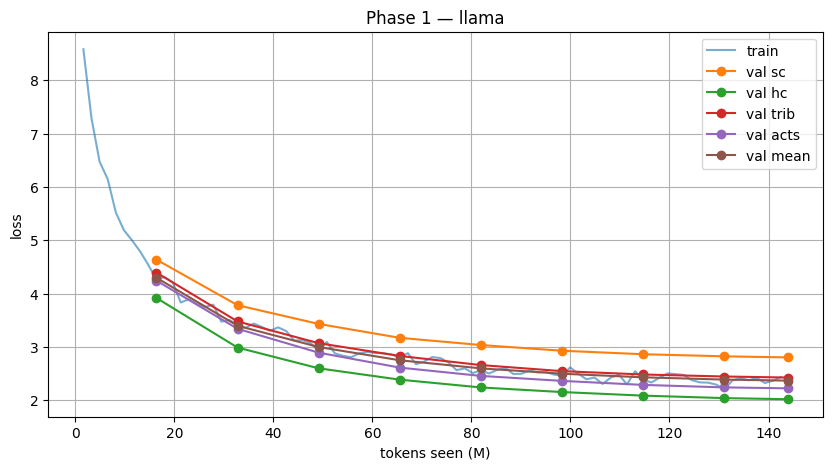

True

In [11]:
import matplotlib.pyplot as plt
h = state["history"]
tr = [(x["tokens"] / 1e6, x["loss"]) for x in h if "loss" in x]
ev = [(x["tokens"] / 1e6, x["eval"]) for x in h if "eval" in x]
plt.figure(figsize=(10, 5))
plt.plot(*zip(*tr), label="train", alpha=0.6)
for s in SOURCES + ["mean"]:
    plt.plot([t for t, _ in ev], [e[s] for _, e in ev], marker="o", label=f"val {s}")
plt.xlabel("tokens seen (M)"); plt.ylabel("loss"); plt.title(f"Phase 1 — {ARCH}"); plt.legend(); plt.grid(True)
plt.savefig(f"{WORK}/loss_{ARCH}.png", dpi=150); plt.show()
hub_push(lambda: api.upload_file(path_or_fileobj=f"{WORK}/loss_{ARCH}.png", path_in_repo=f"loss_{ARCH}.png",
                                 repo_id=MODEL_REPO), "loss plot")

## Free the training model before generation

In [12]:
for _name in ("model", "opt", "scaler", "VAL_SET", "decay", "no_decay", "loss", "batch"):
    globals().pop(_name, None)
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory still allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

GPU memory still allocated: 0.46 GB


# Part B — Generate, evaluate locally, build submission.zip
1. Generates on the local held-out set (`heldout_prompts.json`) and scores it with the official Phase-1 metrics.
2. Generates on the official test prompts, validates IDs, writes `prediction.json` and `submission.zip`.

Uses the `best/` checkpoint saved by Part A in this session if there is one, otherwise downloads `best/` from the Hub
(so Part B can also be run on its own, or while training is still running on another account).

In [13]:
RUN_TAG = "v1"          # name for this submission (stored in the HF repo with the scores)

# Decoding configurations to compare on the held-out set — YOUR CHOICE.
DECODE_CONFIGS = {
    "greedy_rp1.2": dict(do_sample=False, repetition_penalty=1.2, no_repeat_ngram_size=0),
    "greedy_ngram4": dict(do_sample=False, repetition_penalty=1.0, no_repeat_ngram_size=4),
}
HELDOUT_LIMIT = 400     # how many held-out examples to score per config
TARGET_WORDS = 128
MAX_NEW_TOKENS = 224    # must cover 128 words (check the words/token printout below)
BATCH = 32

In [14]:
import re, zipfile, sys
OUT = f"{WORK}/gen_{RUN_TAG}"
os.makedirs(OUT, exist_ok=True)

## Load model + data

In [15]:
from transformers import AutoConfig, AutoModelForCausalLM, BartForConditionalGeneration, PreTrainedTokenizerFast

if os.path.exists(f"{WORK}/best/cs781_info.json"):     # saved by Part A in this session = newest best
    mdir = f"{WORK}/best"
else:
    mdir = os.path.join(snapshot_download(MODEL_REPO, token=HF_TOKEN, allow_patterns=["best/*"]), "best")
info = json.load(open(f"{mdir}/cs781_info.json")); print(info)
cfg = AutoConfig.from_pretrained(mdir)
arch = getattr(cfg, "cs781_arch", ARCH)
tok = PreTrainedTokenizerFast.from_pretrained(mdir)
EOS_ID, PAD_ID = tok.eos_token_id, tok.pad_token_id
device = "cuda"
if arch == "bart":
    model = BartForConditionalGeneration.from_pretrained(mdir)
    MAX_PROMPT_TOKENS = SRC_MAX                   # encoder length used in training
else:
    model = AutoModelForCausalLM.from_pretrained(mdir)
    MAX_PROMPT_TOKENS = cfg.max_position_embeddings - MAX_NEW_TOKENS
model = model.to(device=device, dtype=torch.float16).eval()
print(arch, f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M params, max prompt tokens {MAX_PROMPT_TOKENS}")

data_dir = snapshot_download(DATA_REPO, repo_type="dataset", token=HF_TOKEN,
                             allow_patterns=["heldout_*.json", "meta.json"])
heldout_prompts = json.load(open(f"{data_dir}/heldout_prompts.json", encoding="utf-8"))
heldout_truth = json.load(open(f"{data_dir}/heldout_truth.json", encoding="utf-8"))
keys = list(heldout_prompts)[:HELDOUT_LIMIT] if HELDOUT_LIMIT < len(heldout_prompts) else list(heldout_prompts)
# keep the per-source balance when limiting
if HELDOUT_LIMIT < len(heldout_prompts):
    by_src = {}
    for k in heldout_prompts: by_src.setdefault(k.split("_")[0], []).append(k)
    per = HELDOUT_LIMIT // len(by_src)
    keys = [k for v in by_src.values() for k in v[:per]]

test_path = hf_hub_download("Exploration-Lab/CS-781-Capstone", "Phase_1_Pretraining/Test/test.json",
                            repo_type="dataset", token=HF_TOKEN)
test_data = json.load(open(test_path, encoding="utf-8"))
print("held-out:", len(keys), " test:", len(test_data))

s = [heldout_truth[k]["text"] for k in keys[:100]]
print("tokens per word on references: %.3f" % (sum(len(tok.encode(x)) for x in s) / sum(len(x.split()) for x in s)))

{'step': 2196, 'val_loss': 2.3695422977209093, 'arch': 'llama', 'params': 109529856, 'tokens_seen': 143917056}


Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

llama 109.5M params, max prompt tokens 800


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

held-out: 373  test: 1000
tokens per word on references: 1.213


## Generation
Prompts are truncated from the **left** (keep the end of the prompt, which is what the continuation follows) and
decoder-only batches are **left-padded**. EOS is blocked until `MAX_NEW_TOKENS` so outputs are never cut short.

In [16]:
from transformers import LogitsProcessorList, RepetitionPenaltyLogitsProcessor, NoRepeatNGramLogitsProcessor

def encode_prompts(prompts):
    ids = [tok.encode(p, add_special_tokens=False)[-MAX_PROMPT_TOKENS:] for p in prompts]
    L = max(len(x) for x in ids)
    if arch == "bart":   # encoder: right padding
        inp = torch.tensor([x + [PAD_ID] * (L - len(x)) for x in ids])
        att = torch.tensor([[1] * len(x) + [0] * (L - len(x)) for x in ids])
    else:                # decoder: left padding
        inp = torch.tensor([[PAD_ID] * (L - len(x)) + x for x in ids])
        att = torch.tensor([[0] * (L - len(x)) + [1] * len(x) for x in ids])
    return inp.to(device), att.to(device)

@torch.inference_mode()
def prefixlm_generate(inp, att, dc):
    """Prompt = bidirectional prefix (as in training), then causal decoding with the KV cache."""
    B, L = inp.shape
    procs = LogitsProcessorList()
    if dc.get("repetition_penalty", 1.0) != 1.0: procs.append(RepetitionPenaltyLogitsProcessor(dc["repetition_penalty"]))
    if dc.get("no_repeat_ngram_size", 0) > 0: procs.append(NoRepeatNGramLogitsProcessor(dc["no_repeat_ngram_size"]))
    valid = att.bool()
    mask4d = (valid[:, None, None, :] | torch.eye(L, dtype=torch.bool, device=device)[None, None])  # pad queries see themselves
    pos = (att.cumsum(-1) - 1).clamp(min=0)
    out = model(input_ids=inp, attention_mask=mask4d, position_ids=pos, use_cache=True)
    past, logits = out.past_key_values, out.logits[:, -1].float()
    seq, gen, att2d, last_pos = inp, [], att, pos[:, -1]
    for t in range(MAX_NEW_TOKENS):
        scores = procs(seq, logits)
        scores[:, EOS_ID] = -float("inf"); scores[:, PAD_ID] = -float("inf")
        if dc.get("do_sample"):
            probs = torch.softmax(scores / dc.get("temperature", 1.0), -1)
            nxt = torch.multinomial(probs, 1)
        else:
            nxt = scores.argmax(-1, keepdim=True)
        gen.append(nxt); seq = torch.cat([seq, nxt], 1)
        att2d = torch.cat([att2d, torch.ones_like(nxt)], 1); last_pos = last_pos + 1
        out = model(input_ids=nxt, attention_mask=att2d, position_ids=last_pos[:, None], past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[:, -1].float()
    return torch.cat(gen, 1)

@torch.inference_mode()
def generate_batch(prompts, dc):
    inp, att = encode_prompts(prompts)
    if arch == "prefixlm":
        new = prefixlm_generate(inp, att, dc)
    else:
        kw = dict(max_new_tokens=MAX_NEW_TOKENS, min_new_tokens=MAX_NEW_TOKENS, pad_token_id=PAD_ID,
                  eos_token_id=EOS_ID, suppress_tokens=[PAD_ID], **dc)
        out = model.generate(input_ids=inp, attention_mask=att, **kw)
        new = out if arch == "bart" else out[:, inp.shape[1]:]
    texts = []
    for row in new.tolist():
        words = tok.decode(row, skip_special_tokens=True).split()[:TARGET_WORDS]
        texts.append(" ".join(words) if words else "the")   # evaluator rejects empty strings
    return texts

def run(prompt_dict, ids, dc, label):
    preds, t0 = {}, time.time()
    for i in range(0, len(ids), BATCH):
        chunk = ids[i:i + BATCH]
        for k, txt in zip(chunk, generate_batch([prompt_dict[k]["text"] for k in chunk], dc)):
            preds[str(k)] = {"text": txt}
        print(f"\r{label}: {min(i+BATCH, len(ids))}/{len(ids)}  {time.time()-t0:.0f}s", end="")
    print()
    return preds

## Official Phase-1 metrics (same code as `evaluate_phase1.py`)

In [17]:
try:
    import bert_score
except ImportError as e:
    bert_score = None; print("bert-score not importable, BERTScore will be skipped:", e)
from collections import Counter

def lcs_length(a, b):
    if not a or not b: return 0
    if len(a) < len(b): a, b = b, a
    masks = {}
    for j, t in enumerate(a): masks[t] = masks.get(t, 0) | (1 << j)
    state = 0
    for t in b:
        m = masks.get(t, 0); x = m | state; y = (state << 1) | 1; state = x & ~(x - y)
    return bin(state).count("1")

def rouge_l_f1(p, r):
    pt, rt = p.split(), r.split()
    if not pt or not rt: return 0.0
    l = lcs_length(pt, rt)
    if not l: return 0.0
    pp, rr = l / len(pt), l / len(rt)
    return 2 * pp * rr / (pp + rr)

def ngrams(t, n): return Counter(tuple(t[i:i+n]) for i in range(len(t)-n+1)) if len(t) >= n else Counter()

def bleu4(preds, refs):
    clipped = [0]*4; totals = [0]*4; pl = rl = 0
    for p, r in zip(preds, refs):
        pl += len(p); rl += len(r)
        for n in range(1, 5):
            pn, rn = ngrams(p, n), ngrams(r, n); totals[n-1] += sum(pn.values())
            for g, c in pn.items(): clipped[n-1] += min(c, rn.get(g, 0))
    prec = [clipped[i]/totals[i] if totals[i] else 0.0 for i in range(4)]
    if any(x <= 0 for x in prec) or pl == 0: return 0.0
    bp = 1.0 if pl > rl else math.exp(1.0 - rl/pl)
    return bp * math.exp(sum(math.log(x) for x in prec) / 4)

def score(pred, truth):
    ids = list(truth)
    P = [pred[i]["text"].strip() for i in ids]; R = [truth[i]["text"].strip() for i in ids]
    out = {}
    try:   # a BERTScore failure (e.g. library/version clash) must not block writing the submission
        _, _, f = bert_score.score(P, R, lang="en", batch_size=32, verbose=False, device="cuda")
        out["bertscore_f1"] = float(f.mean())
    except Exception as e:
        f = None; print("  !! BERTScore failed, only ROUGE-L / BLEU-4 reported:", repr(e))
    out["rougeL_f1"] = float(np.mean([rouge_l_f1(p, r) for p, r in zip(P, R)]))
    out["bleu4"] = bleu4([p.split() for p in P], [r.split() for r in R])
    for src in sorted({i.split("_")[0] for i in ids}) if f is not None else []:   # per-source BERTScore (report material)
        idx = [j for j, i in enumerate(ids) if i.startswith(src + "_")]
        out[f"bs_{src}"] = float(f[idx].mean())
    return out

## 1) Compare decoding configs on the local held-out set

In [18]:
truth_sub = {k: heldout_truth[k] for k in keys}
# saved so the official checker can be run on them too:  evaluate_phase1.py --truth heldout_truth.json --prediction heldout_pred_<config>.json
json.dump(truth_sub, open(f"{OUT}/heldout_truth.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
results = {}
for name, dc in DECODE_CONFIGS.items():
    preds = run(heldout_prompts, keys, dc, name)
    json.dump(preds, open(f"{OUT}/heldout_pred_{name}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    results[name] = score(preds, truth_sub)
    print(name, {k: round(v, 4) for k, v in results[name].items()})
    print("  sample:", preds[keys[0]]["text"][:300])
json.dump({"model_info": info, "decode_configs": DECODE_CONFIGS, "heldout": results},
          open(f"{OUT}/heldout_scores.json", "w"), indent=2)

greedy_rp1.2: 373/373  60s


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

greedy_rp1.2 {'bertscore_f1': 0.8224, 'rougeL_f1': 0.1829, 'bleu4': 0.0548, 'bs_acts': 0.814, 'bs_hc': 0.8305, 'bs_sc': 0.8201, 'bs_trib': 0.8226}
  sample: he knew was that he did not know about the order he could have been convicted under s. 138 of the Act. But there is nothing to indicate that the accused were guilty of contempt. The High Court observed that the order of dismissal was based upon the evidence adduced by the prosecution and the learned
greedy_ngram4: 373/373  60s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy_ngram4 {'bertscore_f1': 0.8309, 'rougeL_f1': 0.1995, 'bleu4': 0.0509, 'bs_acts': 0.8291, 'bs_hc': 0.8362, 'bs_sc': 0.8272, 'bs_trib': 0.8305}
  sample: he had said was that the order was not made by the subordinate court, the order could not have been passed by the subordinate judge. The High Court was, therefore, right in holding that the order of dismissal was not made in accordance with law. The High court was, therefore right in holding the ord


## 2) Generate the official test predictions with the chosen config
Set `CHOSEN` yourself after looking at the table above.

In [19]:
SELECT_BY = "bertscore_f1" if all("bertscore_f1" in r for r in results.values()) else "rougeL_f1"
CHOSEN = max(results, key=lambda n: results[n][SELECT_BY])   # or set a name explicitly
print("Using decode config:", CHOSEN, DECODE_CONFIGS[CHOSEN])
test_ids = list(test_data)
predictions = run(test_data, test_ids, DECODE_CONFIGS[CHOSEN], "test")

# validation (same checks as the evaluator / Codabench)
assert set(predictions) == set(map(str, test_data)), "ID mismatch"
assert all(isinstance(v["text"], str) and v["text"].strip() for v in predictions.values()), "empty prediction"
wl = [len(v["text"].split()) for v in predictions.values()]
print(f"words per prediction: min {min(wl)} mean {np.mean(wl):.1f} max {max(wl)}")

pred_path = f"{OUT}/prediction.json"
json.dump(predictions, open(pred_path, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
zip_path = f"{OUT}/submission.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(pred_path, arcname="prediction.json")
with zipfile.ZipFile(zip_path) as z: assert z.namelist() == ["prediction.json"]
print("Ready:", zip_path)

# keep a record of every submission (config + local scores) next to the model
json.dump({"model_info": info, "decode": {CHOSEN: DECODE_CONFIGS[CHOSEN]}, "heldout": results[CHOSEN]},
          open(f"{OUT}/submission_record.json", "w"), indent=2)
hub_push(lambda: api.upload_folder(folder_path=OUT, path_in_repo=f"submissions/{RUN_TAG}", repo_id=MODEL_REPO),
         "submission record")

Using decode config: greedy_ngram4 {'do_sample': False, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 4}
test: 1000/1000  155s
words per prediction: min 78 mean 127.6 max 128
Ready: /content/p1_train/gen_v1/submission.zip


True

In [20]:
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download manually from", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>